# Symptom checker: exploratory data analysis and leakage audit

Kaggle *Disease Prediction Using Machine Learning*: 41 diseases described by 132 binary symptoms. Many tutorials report ~100% accuracy on it. This notebook shows why that number is meaningless and how we evaluate honestly instead.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from medml.data import load

sns.set_theme(style="whitegrid", palette="crest")
pd.set_option("display.precision", 2)
from medml.data import _clean_symptom_frame
from medml.paths import RAW_DIR

## 1. The raw files are mostly duplicates

In [2]:
train = _clean_symptom_frame(pd.read_csv(RAW_DIR / "symptoms_train.csv"))
test = _clean_symptom_frame(pd.read_csv(RAW_DIR / "symptoms_test.csv"))
print(f"train rows: {len(train):,}   unique: {len(train.drop_duplicates()):,}")
print(f"test rows:  {len(test):,}    unique: {len(test.drop_duplicates()):,}")
in_train = test.merge(train.drop_duplicates(), how="left", indicator=True)["_merge"].eq("both")
print(f"test rows that also appear verbatim in train: {in_train.sum()} / {len(test)}")

train rows: 4,920   unique: 304
test rows:  42    unique: 42
test rows that also appear verbatim in train: 41 / 42


C:\Users\ysrkh\AppData\Local\Temp\ipykernel_31112\3338406126.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  in_train = test.merge(train.drop_duplicates(), how='left', indicator=True)['_merge'].eq('both')
C:\Users\ysrkh\AppData\Local\Temp\ipykernel_31112\3338406126.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  in_train = test.merge(train.drop_duplicates(), how='left', indicator=True)['_merge'].eq('both')


Because 41 of the 42 test rows are copies of training rows, a model that simply *memorises* the training file scores ~100%. That says nothing about how it handles a new patient.

## 2. Cleaned dataset

In [3]:
data = load("symptom")
for step in data.cleaning_log:
    print("-", step)
print(data.X.shape, "classes:", len(data.class_names))

- Fixed malformed column names (e.g. 'spotting_ urination', 'dischromic _patches') and disease-name typos (e.g. 'Osteoarthristis', 'Peptic ulcer diseae')
- Dropped the empty 'fluid_overload' column (its duplicate 'fluid_overload.1' holds the data)
- Merged the train and test files and removed exact duplicates: 4962 -> 305 unique rows. The original test file was almost entirely copies of training rows, which makes ~100% accuracy meaningless
- Evaluation uses stratified cross-validation on unique rows plus a robustness test that hides some of the patient's symptoms
(305, 131) classes: 41


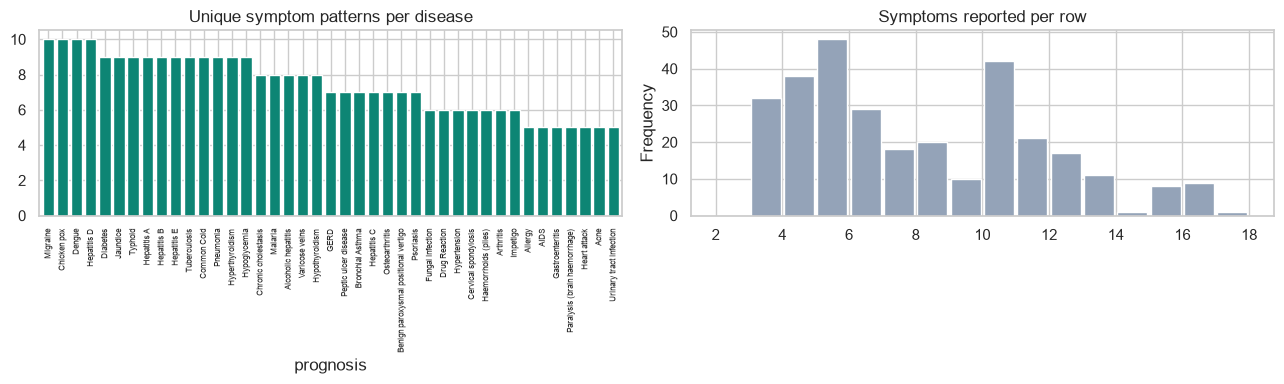

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = data.y.map(dict(enumerate(data.class_names))).value_counts()
counts.plot.bar(ax=axes[0], color="#0d8574", width=0.8)
axes[0].set_title("Unique symptom patterns per disease")
axes[0].tick_params(axis="x", labelsize=6)
data.X.sum(axis=1).plot.hist(bins=range(2, 19), ax=axes[1], color="#94a3b8", rwidth=0.9)
axes[1].set_title("Symptoms reported per row")
plt.tight_layout()

## 3. Most common symptoms

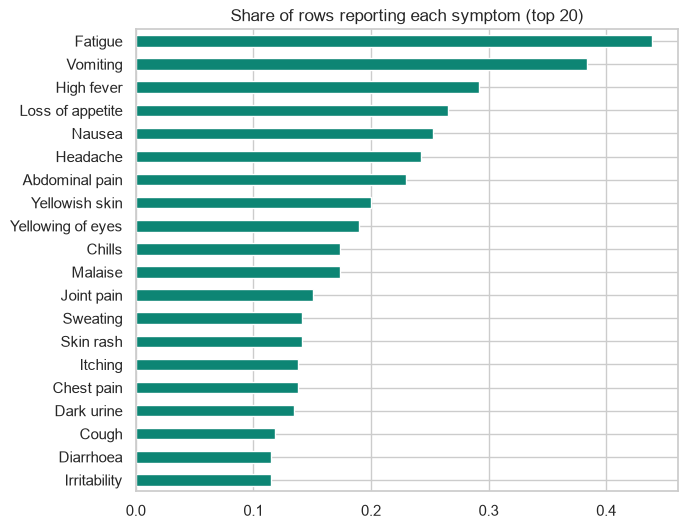

In [5]:
from medml.features import humanize_symptom

top = data.X.mean().sort_values(ascending=False).head(20)
top.index = [humanize_symptom(s) for s in top.index]
top.plot.barh(figsize=(7, 6), color="#0d8574").invert_yaxis()
plt.title("Share of rows reporting each symptom (top 20)")
plt.show()

## 4. Disease x symptom profile (sample)

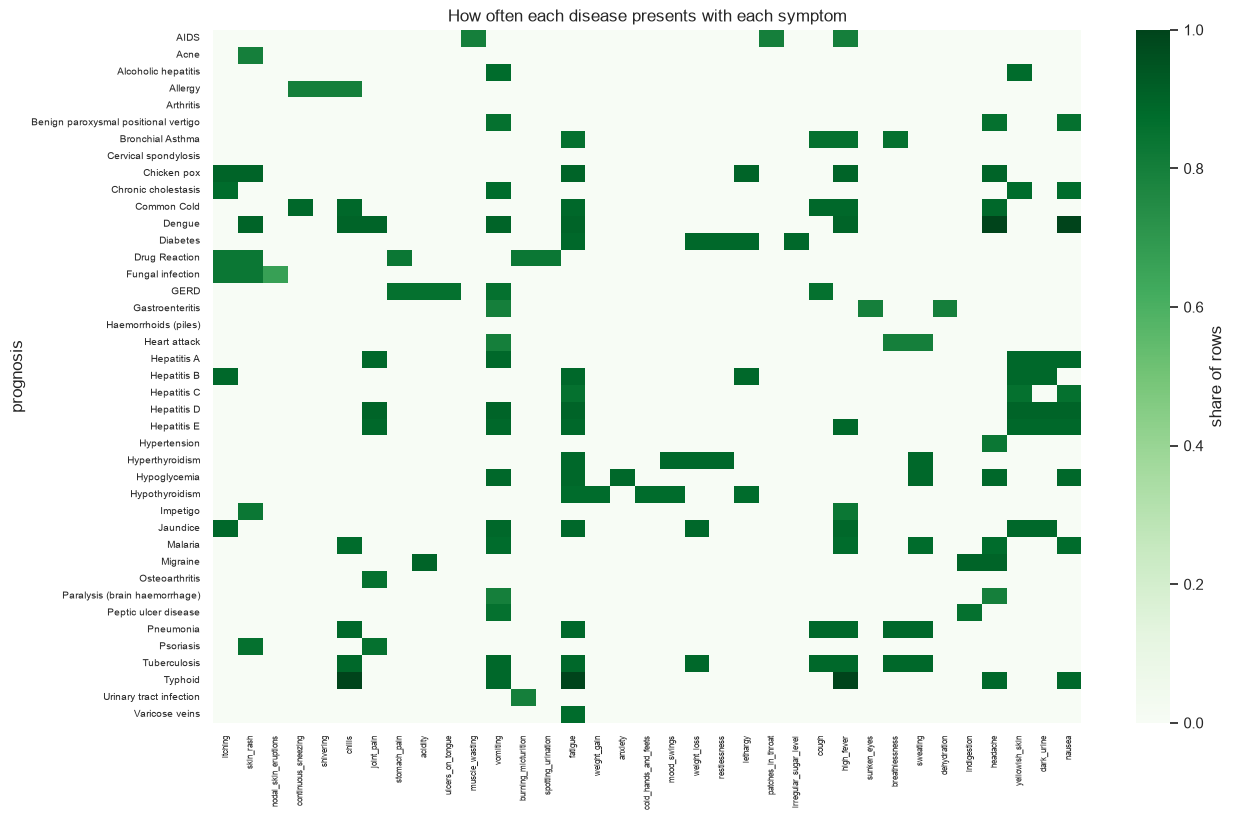

In [6]:
profile = data.X.groupby(data.y.map(dict(enumerate(data.class_names)))).mean()
keep = profile.columns[profile.max() > 0.5][:35]
plt.figure(figsize=(14, 9))
sns.heatmap(profile[keep], cmap="Greens", cbar_kws={"label": "share of rows"})
plt.xticks(fontsize=6)
plt.yticks(fontsize=7)
plt.title("How often each disease presents with each symptom")
plt.show()

## Observations and evaluation plan

- After de-duplication there are only **~305 unique patterns** (5-10 per disease). Each disease has a near-fixed symptom 'template', so the task is closer to a lookup than to real-world diagnosis.
- We therefore (1) de-duplicate before splitting, (2) use stratified cross-validation on unique rows, and (3) run a **robustness test**: hide 1-3 of each test patient's symptoms (real patients rarely report everything) and measure top-1 / top-3 accuracy.
- Results are in `ml/reports/symptom/robustness.png` and `docs/06-model-evaluation.md`.